256 left, 256 right


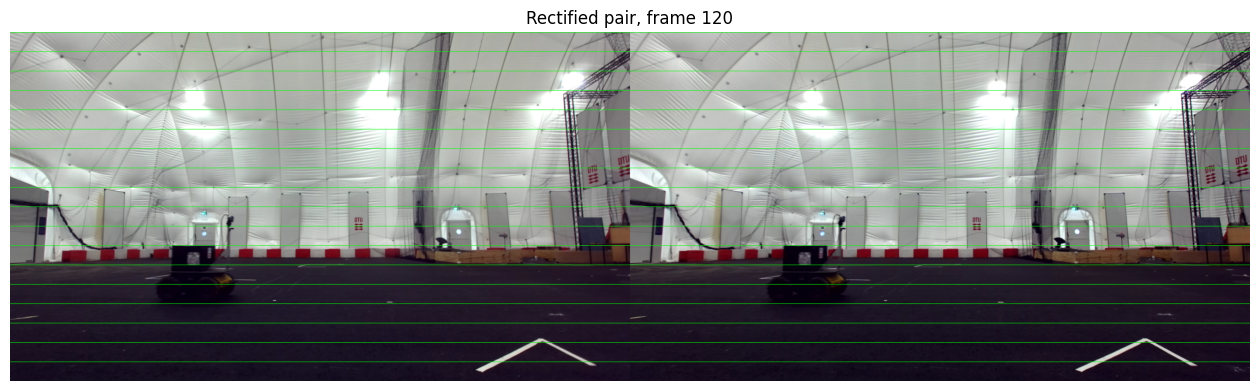

In [1]:
import glob
import cv2
import numpy as np
from matplotlib import pyplot as plt
from stereo import load_rectification, rectify

SEQ = "1_no_obstacle"
DATA = f"{SEQ}/{SEQ}"   # your folders are 1_no_obstacle/1_no_obstacle/left and /right
lefts = sorted(glob.glob(f"{DATA}/left/*.png"))
rights = sorted(glob.glob(f"{DATA}/right/*.png"))
print(len(lefts), "left,", len(rights), "right")

# Calibration from Tim's notebook
mapL, mapR, Q = load_rectification("stereo_calib.npz")

def load_pair(i):
    """Read and rectify stereo pair number i."""
    return rectify(cv2.imread(lefts[i]), cv2.imread(rights[i]), mapL, mapR)

# Frame 120: the robot is in the middle of the image
rectL, rectR = load_pair(120)

# After rectification, the same point must lie on the same row in both images
both = np.hstack((rectL, rectR))
for y in range(0, both.shape[0], 40):
    cv2.line(both, (0, y), (both.shape[1], y), (0, 255, 0), 1)
plt.figure(figsize=(16, 5))
plt.imshow(both[..., ::-1])
plt.title("Rectified pair, frame 120")
plt.axis("off")
plt.show()

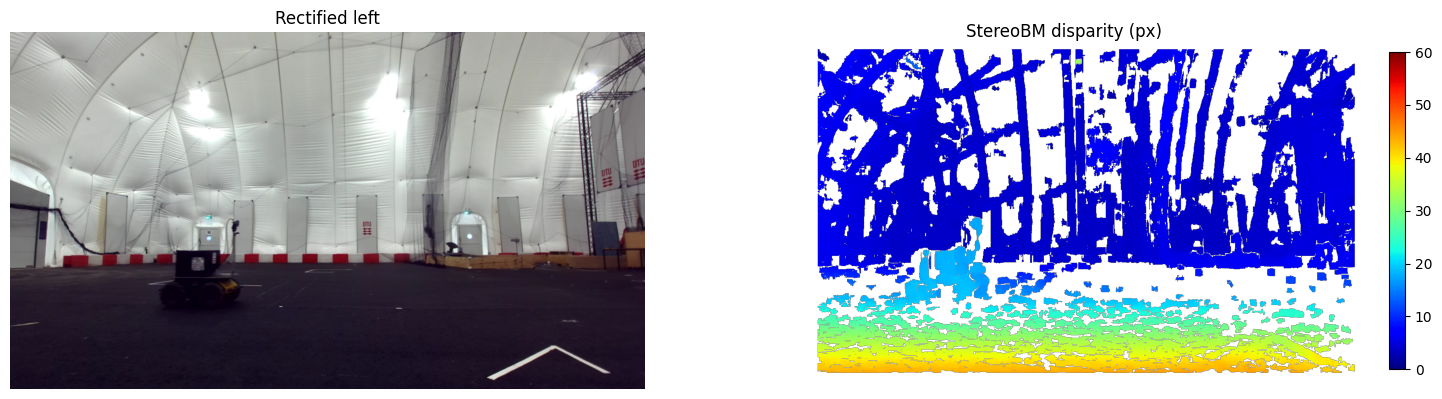

f = 628.1 px, baseline = 119.4 mm
robot disparity ≈ 18.5 px  ->  depth Z = f*B/d ≈ 4.05 m


In [2]:
gray_left = cv2.cvtColor(rectL, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(rectR, cv2.COLOR_BGR2GRAY)

min_disp = 0
num_disp = 6 * 16      # must be a multiple of 16
block_size = 15        # must be odd
stereo = cv2.StereoBM_create(numDisparities=num_disp, blockSize=block_size)
stereo.setMinDisparity(min_disp)
stereo.setDisp12MaxDiff(1)
stereo.setUniquenessRatio(10)
stereo.setSpeckleRange(2)
stereo.setSpeckleWindowSize(100)

# StereoBM returns disparity * 16
disp = stereo.compute(gray_left, gray_right).astype(np.float32) / 16.0

fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].imshow(rectL[..., ::-1]); ax[0].set_title("Rectified left"); ax[0].axis("off")
im = ax[1].imshow(np.where(disp > 0, disp, np.nan), cmap="jet", vmin=0, vmax=60)
ax[1].set_title("StereoBM disparity (px)"); ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.025)
plt.show()

# Quick check on the robot: disparity and depth at a point on its body
f_px = Q[2, 3]          # focal length in pixels
B_mm = 1.0 / Q[3, 2]    # baseline in mm
u, v = 400, 500         # a pixel on the robot in frame 120
patch = disp[v-10:v+10, u-10:u+10]
d = np.median(patch[patch > 0])
print(f"f = {f_px:.1f} px, baseline = {B_mm:.1f} mm")
print(f"robot disparity ≈ {d:.1f} px  ->  depth Z = f*B/d ≈ {f_px * B_mm / d / 1000:.2f} m")

seq1_frame120.ply saved with 508247 points


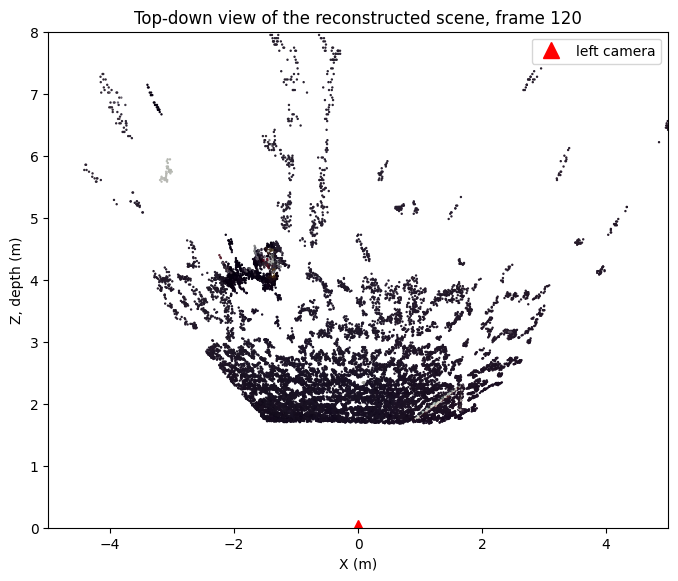

In [3]:
def export_pointcloud(disparity_map, colors, Q, filename):
    """Reproject a disparity map to 3D with Q and save it as a coloured .ply (as in the block-matching exercise)."""
    ply_header = """ply
format ascii 1.0
element vertex %(vert_num)d
property float x
property float y
property float z
property uchar red
property uchar green
property uchar blue
end_header
"""
    points = cv2.reprojectImageTo3D(disparity_map, Q)   # X, Y, Z in mm (Y points down)

    # keep only valid disparities and a sensible depth range (0.5 m to 30 m)
    mask = (disparity_map > 0) & (points[..., 2] > 500) & (points[..., 2] < 30000)
    out_points = points[mask]
    out_colors = colors[mask]

    # flip Y and Z so the cloud is upright in MeshLab (same idea as the flip in the ICP exercise)
    out_points = out_points * np.array([1, -1, -1])

    verts = np.hstack([out_points, out_colors])
    with open(filename, "wb") as fh:
        fh.write((ply_header % dict(vert_num=len(verts))).encode("utf-8"))
        np.savetxt(fh, verts, fmt="%f %f %f %d %d %d")
    print(f"{filename} saved with {len(verts)} points")
    return points, mask


colors_rgb = cv2.cvtColor(rectL, cv2.COLOR_BGR2RGB)
points, mask = export_pointcloud(disp, colors_rgb, Q, "seq1_frame120.ply")

# Top-down view of the scene (X vs depth Z), useful as a figure for the report
pts = points[mask]
col = colors_rgb[mask] / 255
sub = np.random.default_rng(0).choice(len(pts), min(60000, len(pts)), replace=False)
plt.figure(figsize=(8, 7))
plt.scatter(pts[sub, 0] / 1000, pts[sub, 2] / 1000, c=col[sub], s=0.5)
plt.plot(0, 0, "r^", ms=12, label="left camera")
plt.xlabel("X (m)"); plt.ylabel("Z, depth (m)")
plt.title("Top-down view of the reconstructed scene, frame 120")
plt.xlim(-5, 5); plt.ylim(0, 8); plt.gca().set_aspect("equal"); plt.legend()
plt.show()

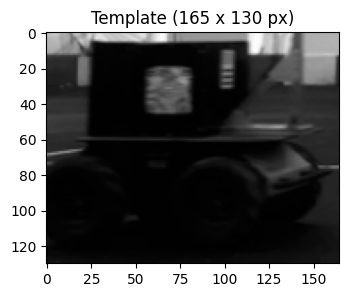

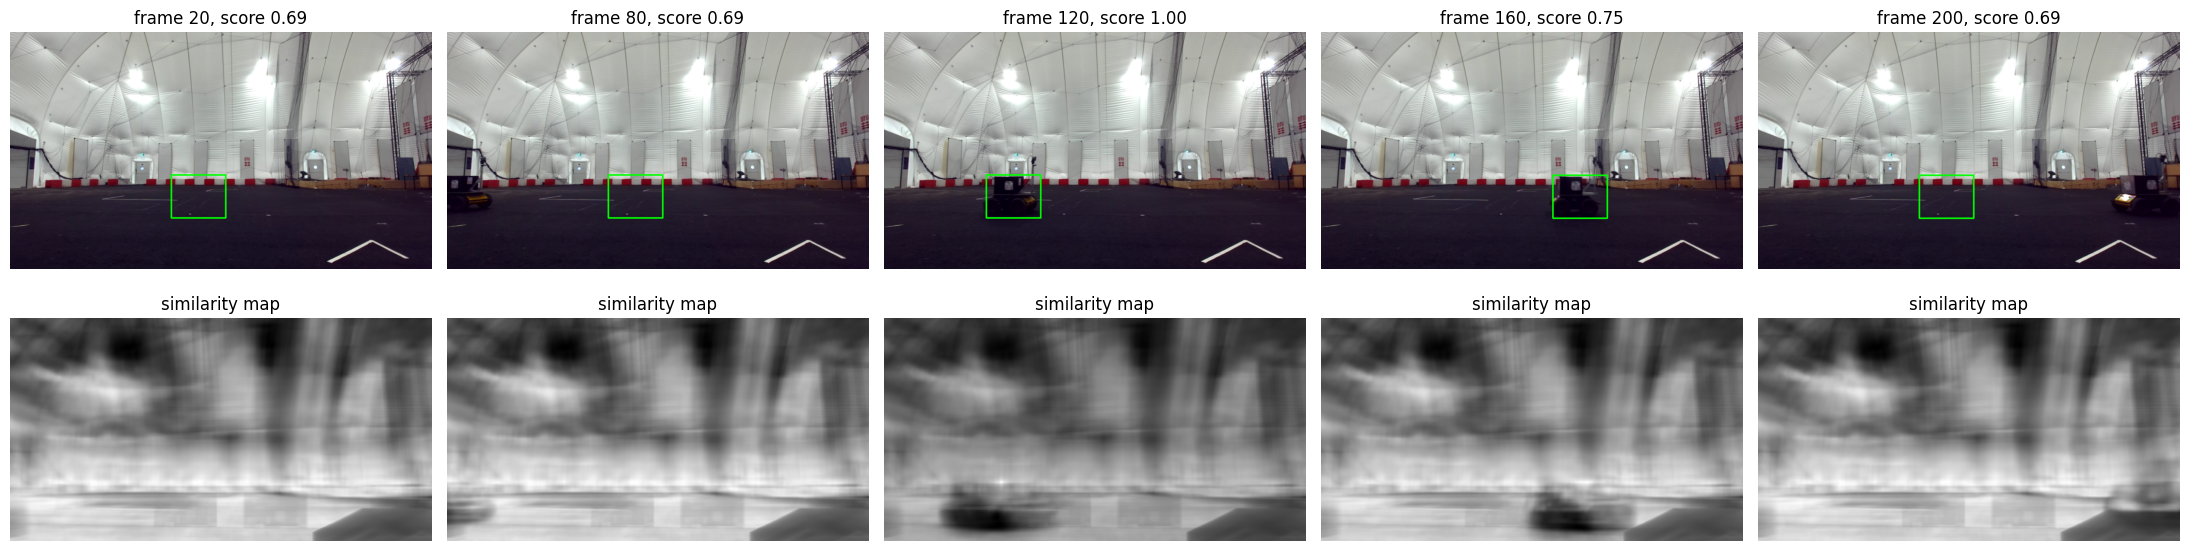

In [4]:
# 1. Template: crop the robot body from frame 120 (without the thin mast on top)
gray120 = cv2.cvtColor(rectL, cv2.COLOR_BGR2GRAY)
y0, y1, x0, x1 = 435, 565, 310, 475
template = gray120[y0:y1, x0:x1]
th, tw = template.shape

plt.figure(figsize=(4, 3))
plt.imshow(template, cmap="gray")
plt.title(f"Template ({tw} x {th} px)")
plt.show()


def match_robot(gray, template):
    """Template matching as in the exercise. Returns score map, best score and box (x, y, w, h)."""
    res = cv2.matchTemplate(gray, template, cv2.TM_CCOEFF_NORMED)
    _, max_val, _, max_loc = cv2.minMaxLoc(res)
    return res, max_val, (max_loc[0], max_loc[1], template.shape[1], template.shape[0])


# 2. Test it on a few frames, including one with no robot (frame 20)
test_frames = [20, 80, 120, 160, 200]
fig, ax = plt.subplots(2, len(test_frames), figsize=(22, 6))
for j, i in enumerate(test_frames):
    img = load_pair(i)[0]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    res, score, (x, y, w, h) = match_robot(gray, template)
    vis = cv2.rectangle(img.copy(), (x, y), (x + w, y + h), (0, 255, 0), 4)
    ax[0, j].imshow(vis[..., ::-1]); ax[0, j].set_title(f"frame {i}, score {score:.2f}")
    ax[1, j].imshow(res, cmap="gray"); ax[1, j].set_title("similarity map")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout()
plt.show()


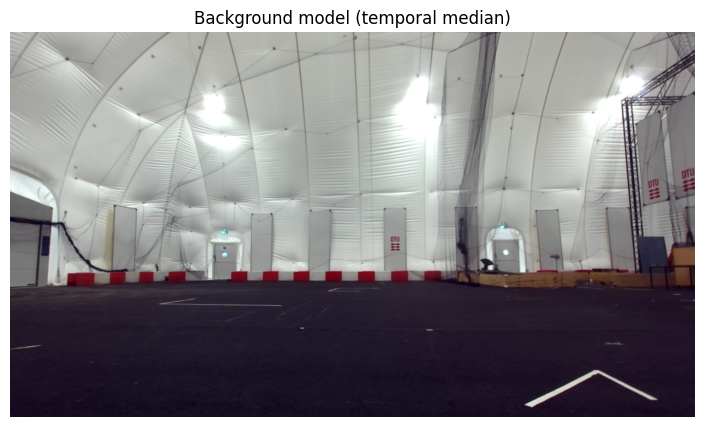

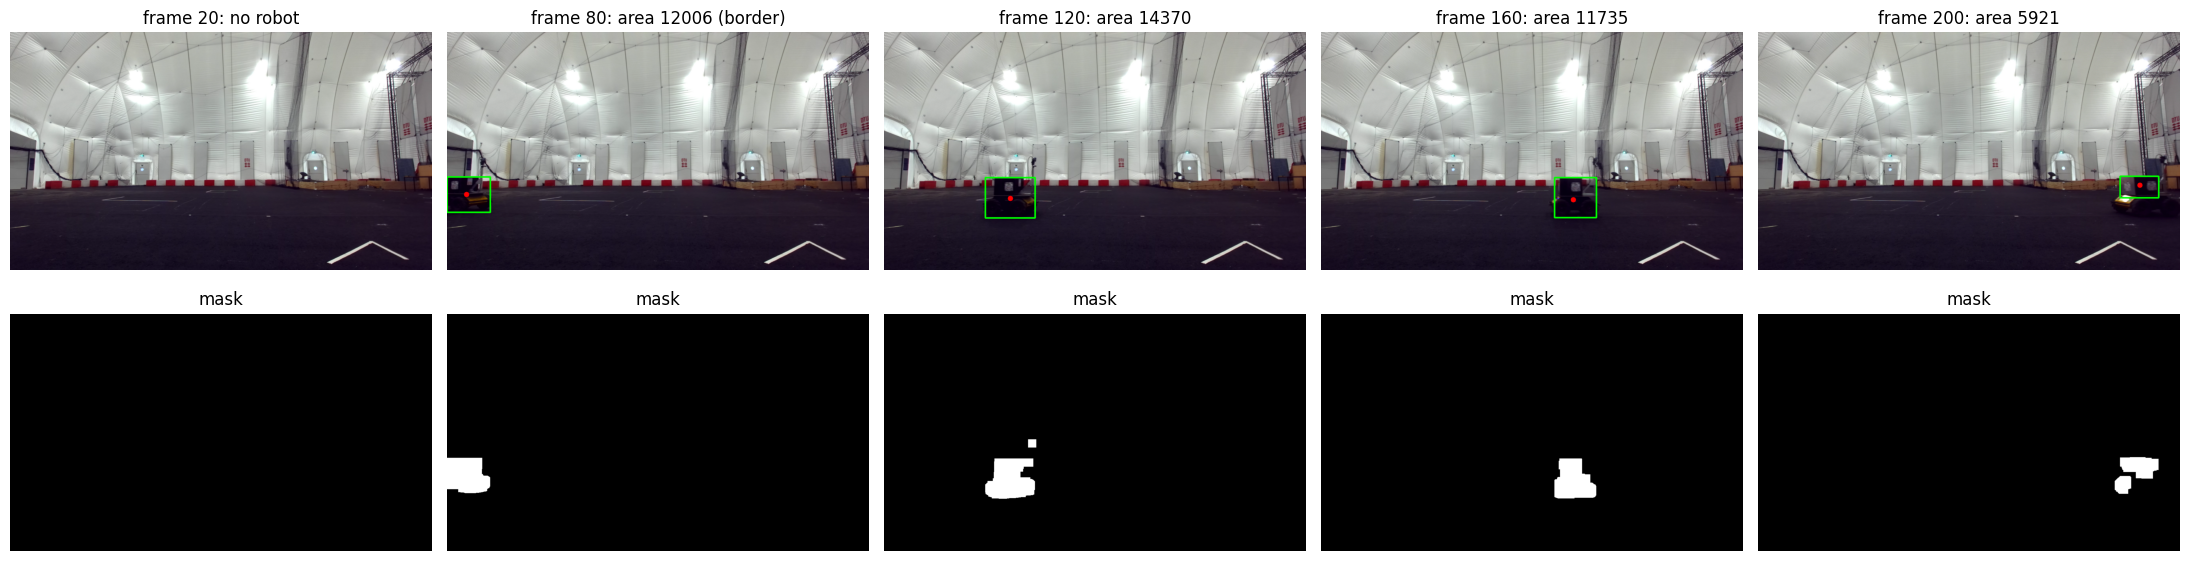

In [5]:
# 1. Background model: per-pixel MEDIAN over time (every 4th frame).
#    The robot covers each pixel for only a few frames, so the median is the empty hall.
bg_frames = [load_pair(i)[0] for i in range(0, len(lefts), 4)]
background = np.median(np.array(bg_frames), axis=0).astype(np.uint8)
del bg_frames

plt.figure(figsize=(10, 5))
plt.imshow(background[..., ::-1]); plt.title("Background model (temporal median)"); plt.axis("off")
plt.show()

# 2. Parameters
DIFF_THR = 25      # grey-level difference that counts as "changed"
MIN_AREA = 800     # smallest blob (px) that can be the robot
K_OPEN = np.ones((3, 3), np.uint8)        # removes single noisy pixels
K_CLOSE = np.ones((15, 15), np.uint8)     # fills holes inside the dark robot body
K_MAST = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25))   # removes the thin mast on top


def foreground_mask(img):
    """Difference to background -> threshold -> morphology (Image Processing lecture)."""
    diff = cv2.absdiff(img, background).max(axis=2)      # largest change over the 3 colour channels
    mask = (diff > DIFF_THR).astype(np.uint8) * 255      # thresholding
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, K_OPEN)    # opening: remove noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, K_CLOSE)  # closing: fill holes
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, K_MAST)    # opening: remove the mast
    return mask


def detect(img):
    """Connected components: the robot is the largest blob. Returns None if there is no robot."""
    mask = foreground_mask(img)
    n, labels, stats, cents = cv2.connectedComponentsWithStats(mask)
    if n < 2:
        return None
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])     # label 0 is the background
    x, y, w, h, area = stats[k]
    if area < MIN_AREA:
        return None
    return {"bbox": (x, y, w, h), "centroid": cents[k], "area": area,
            "mask": labels == k, "border": x <= 1 or x + w >= img.shape[1] - 1}


# 3. Test on the same frames as the template matching
test_frames = [20, 80, 120, 160, 200]
fig, ax = plt.subplots(2, len(test_frames), figsize=(22, 6))
for j, i in enumerate(test_frames):
    img = load_pair(i)[0]
    det = detect(img)
    vis = img.copy()
    title = f"frame {i}: no robot"
    if det:
        x, y, w, h = det["bbox"]
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 4)
        cv2.circle(vis, tuple(int(c) for c in det["centroid"]), 8, (0, 0, 255), -1)
        title = f"frame {i}: area {det['area']}" + (" (border)" if det["border"] else "")
    ax[0, j].imshow(vis[..., ::-1]); ax[0, j].set_title(title)
    ax[1, j].imshow(foreground_mask(img), cmap="gray"); ax[1, j].set_title("mask")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout()
plt.show()

robot detected in 152 frames (66..217)
3D position in   141 frames (77..217)


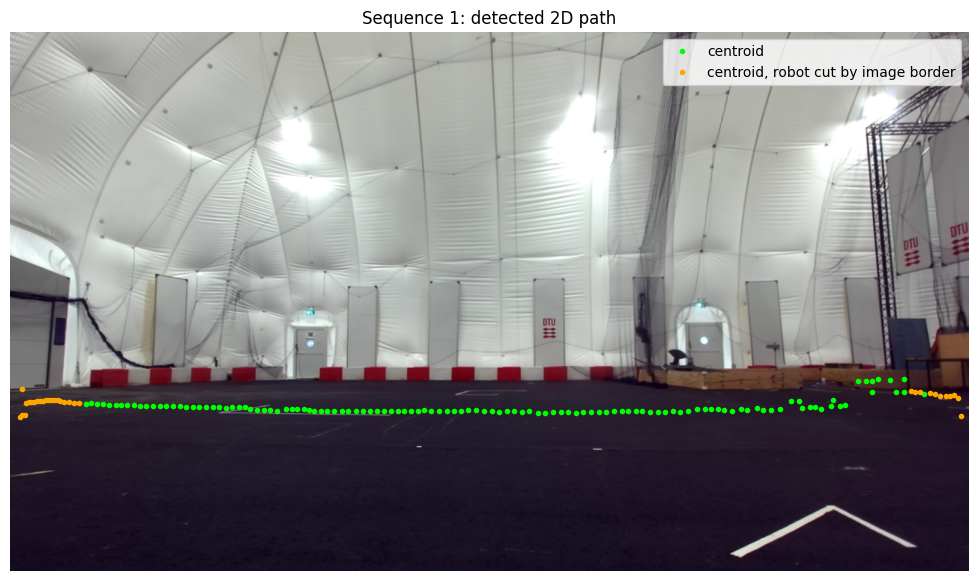

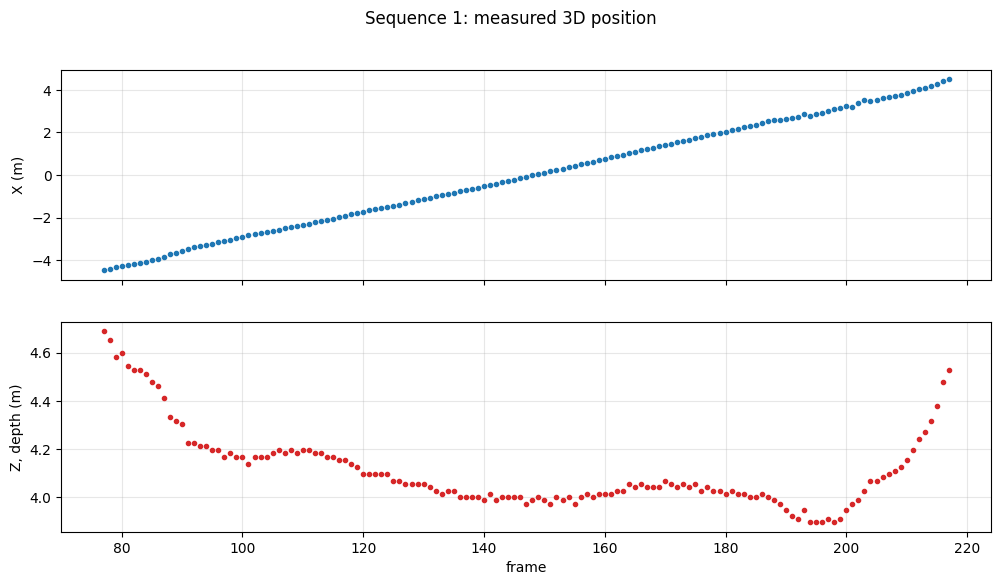

In [6]:
MIN_VALID = 200   # need at least this many valid disparity pixels on the robot


def locate_3d(det, disp):
    """3D position (mm) of a detection: mask centroid + median disparity inside the mask."""
    d = disp[det["mask"]]
    d = d[d > 0]                       # only valid disparities
    if d.size < MIN_VALID:
        return None, np.nan
    d_med = float(np.median(d))
    u, v = det["centroid"]
    X, Y, Z, W = Q @ np.array([u, v, d_med, 1.0])   # same as reprojectImageTo3D, for one pixel
    return np.array([X, Y, Z]) / W, d_med


# Run over the whole sequence (takes about a minute)
results = []
for i in range(len(lefts)):
    rL, rR = load_pair(i)
    det = detect(rL)
    p3d, d_med = None, np.nan
    if det:
        disp_i = stereo.compute(cv2.cvtColor(rL, cv2.COLOR_BGR2GRAY),
                                cv2.cvtColor(rR, cv2.COLOR_BGR2GRAY)).astype(np.float32) / 16.0
        p3d, d_med = locate_3d(det, disp_i)
    results.append({
        "frame": i,
        "detected": det is not None,
        "border": det["border"] if det else False,
        "bbox": det["bbox"] if det else None,
        "uv": det["centroid"] if det else np.array([np.nan, np.nan]),
        "disp": d_med,
        "xyz": p3d if p3d is not None else np.array([np.nan] * 3),
    })

frames = np.array([r["frame"] for r in results])
uv = np.array([r["uv"] for r in results])
xyz = np.array([r["xyz"] for r in results]) / 1000      # metres
border = np.array([r["border"] for r in results])
det_frames = frames[[r["detected"] for r in results]]
xyz_frames = frames[~np.isnan(xyz[:, 2])]
print(f"robot detected in {len(det_frames)} frames ({det_frames.min()}..{det_frames.max()})")
print(f"3D position in   {len(xyz_frames)} frames ({xyz_frames.min()}..{xyz_frames.max()})")

# Plot 1: 2D path of the centroid on the background image
plt.figure(figsize=(14, 7))
plt.imshow(background[..., ::-1])
plt.plot(uv[~border, 0], uv[~border, 1], "o", ms=3, color="lime", label="centroid")
plt.plot(uv[border, 0], uv[border, 1], "o", ms=3, color="orange", label="centroid, robot cut by image border")
plt.legend(); plt.axis("off"); plt.title("Sequence 1: detected 2D path")
plt.show()

# Plot 2: X and Z over time
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(frames, xyz[:, 0], ".", color="tab:blue"); ax[0].set_ylabel("X (m)"); ax[0].grid(alpha=0.3)
ax[1].plot(frames, xyz[:, 2], ".", color="tab:red"); ax[1].set_ylabel("Z, depth (m)"); ax[1].grid(alpha=0.3)
ax[1].set_xlabel("frame"); fig.suptitle("Sequence 1: measured 3D position")
plt.show()

F for 2D (same as Exercise 2d):
 [[1. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 1.]
 [0. 0. 0. 1.]]
H for 2D (same as Exercise 2d):
 [[1. 0. 0. 0.]
 [0. 0. 1. 0.]]


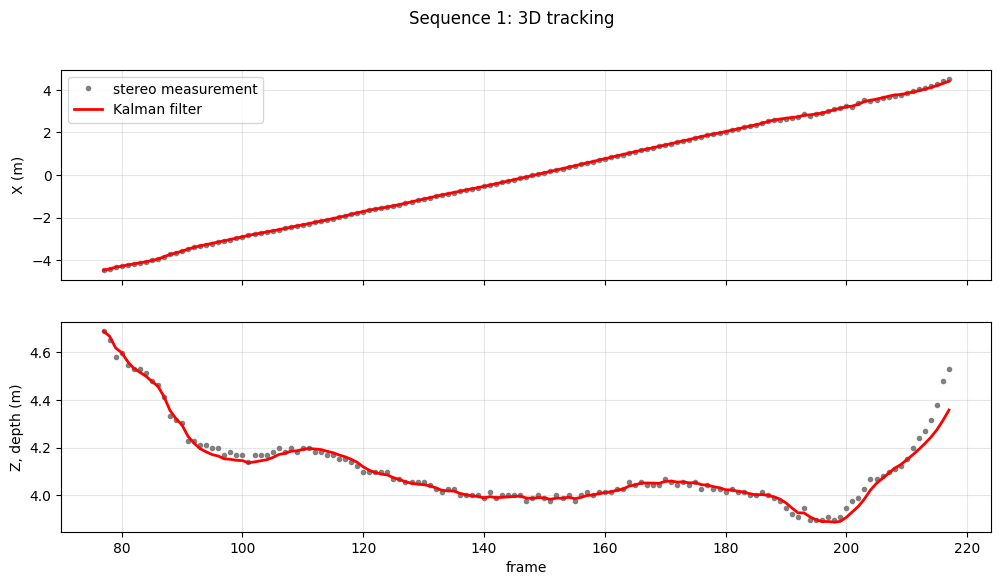

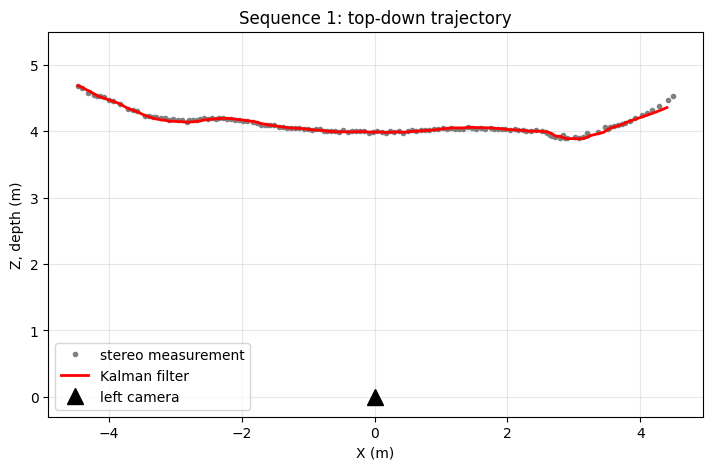

speed: 64.0 ± 8.7 mm/frame
depth: 4.06 ± 0.10 m


In [7]:
# --- Kalman functions from Exercise 2c (week 7), with process noise Q added to predict ---
def update(x, P, Z, H, R):
    y = Z - np.dot(H, x)                            # innovation
    S = np.dot(H, np.dot(P, H.T)) + R               # innovation covariance
    K = np.dot(P, np.dot(H.T, np.linalg.pinv(S)))   # Kalman gain
    x = x + np.dot(K, y)                            # state update
    I = np.eye(P.shape[0])
    P = np.dot((I - np.dot(K, H)), P)               # covariance update
    return [x, P]


def predict(x, P, F, u, Q):
    x = np.dot(F, x) + u                            # predict next state
    P = np.dot(F, np.dot(P, F.T)) + Q               # added: + Q (process noise), as in the lecture
    return [x, P]


def make_matrices(dim, q):
    """F, H, Q for a constant-velocity model, state ordered as in Exercise 2d:
    [pos_1, vel_1, pos_2, vel_2, ...]. One 2x2 block per axis."""
    F1 = np.array([[1, 1], [0, 1]])                       # 1D model from Exercise 2c
    H1 = np.array([[1, 0]])
    Q1 = np.array([[0.25, 0.5], [0.5, 1.0]]) * q**2       # small random acceleration per frame
    F = np.kron(np.eye(dim), F1)                          # block-diagonal, like F in Exercise 2d
    H = np.kron(np.eye(dim), H1)
    Q = np.kron(np.eye(dim), Q1)
    return F, H, Q


F2, H2, Q2 = make_matrices(2, q=0.5)    # 2D: pixels
F3, H3, Q3 = make_matrices(3, q=5.0)    # 3D: millimetres
print("F for 2D (same as Exercise 2d):\n", F2)
print("H for 2D (same as Exercise 2d):\n", H2)

# --- Measurement noise R ---
f_px, B_mm = Q[2, 3], 1.0 / Q[3, 2]     # Q here is still the stereo Q matrix from Step 1
SIGMA_PX = 3.0      # centroid noise (px)
SIGMA_D = 0.25      # disparity noise (px)
BORDER = 25.0       # robot cut by the image border -> trust it 25x less


def R_2d(border):
    return np.eye(2) * SIGMA_PX**2 * (BORDER if border else 1)


def R_3d(p, border):
    Z = p[2]
    s_z = Z**2 / (f_px * B_mm) * SIGMA_D    # depth error grows with Z^2 (from Z = f*B/d)
    s_xy = SIGMA_PX * Z / f_px
    return np.diag([s_xy**2, s_xy**2, s_z**2]) * (BORDER if border else 1)


def start_state(z, R0, vel_var):
    """Initial x and P: position = first measurement, velocity = 0 but very uncertain."""
    dim = len(z)
    x = np.zeros((2 * dim, 1))
    x[0::2, 0] = z                      # positions at indices 0, 2, (4)
    P = np.eye(2 * dim) * vel_var       # large variance for the velocities
    P[0::2, 0::2] = R0                  # position variance = measurement variance
    return x, P


# --- Run the filters over the whole sequence ---
MAX_MISSES = 15     # stop a track after this many frames without a measurement
n = len(results)
kf_uv = np.full((n, 2), np.nan)
kf_xyz = np.full((n, 3), np.nan)
kf_vel = np.full((n, 3), np.nan)
x2 = P2 = x3 = P3 = None
miss2 = miss3 = 0

for k, r in enumerate(results):
    # measurements of this frame (None = no measurement)
    z2 = r["uv"] if r["detected"] else None
    z3 = r["xyz"] if not np.isnan(r["xyz"][0]) else None

    # ---- 2D (pixels) ----
    if x2 is None and z2 is not None:
        x2, P2 = start_state(z2, R_2d(r["border"]), vel_var=30**2)
    elif x2 is not None:
        if z2 is not None:
            x2, P2 = update(x2, P2, z2.reshape(-1, 1), H2, R_2d(r["border"]))
            miss2 = 0
        else:
            miss2 += 1
    if x2 is not None:
        kf_uv[k] = x2[0::2, 0]                          # positions u, v
        x2, P2 = predict(x2, P2, F2, np.zeros_like(x2), Q2)
        u_next = x2[0, 0]
        left_view = u_next < 0 or u_next > rectL.shape[1]   # predicted outside the image
        if miss2 > MAX_MISSES or (left_view and z2 is None):
            x2, miss2 = None, 0
            x3, miss3 = None, 0 

    # ---- 3D (mm) ----
    if x3 is None and z3 is not None:
        x3, P3 = start_state(z3, R_3d(z3, r["border"]), vel_var=200**2)
    elif x3 is not None:
        if z3 is not None:
            x3, P3 = update(x3, P3, z3.reshape(-1, 1), H3, R_3d(z3, r["border"]))
            miss3 = 0
        else:
            miss3 += 1
    if x3 is not None:
        kf_xyz[k] = x3[0::2, 0] / 1000                  # positions X, Y, Z in metres
        kf_vel[k] = x3[1::2, 0]                         # velocities in mm/frame
        x3, P3 = predict(x3, P3, F3, np.zeros_like(x3), Q3)
        if miss3 > MAX_MISSES:
            x3, miss3 = None, 0

# --- Plots ---
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for a, j, name in [(ax[0], 0, "X (m)"), (ax[1], 2, "Z, depth (m)")]:
    a.plot(frames, xyz[:, j], ".", color="grey", label="stereo measurement")
    a.plot(frames, kf_xyz[:, j], "-", color="red", lw=2, label="Kalman filter")
    a.set_ylabel(name); a.grid(alpha=0.3)
ax[0].legend(); ax[1].set_xlabel("frame")
fig.suptitle("Sequence 1: 3D tracking")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(xyz[:, 0], xyz[:, 2], ".", color="grey", label="stereo measurement")
plt.plot(kf_xyz[:, 0], kf_xyz[:, 2], "-", color="red", lw=2, label="Kalman filter")
plt.plot(0, 0, "k^", ms=12, label="left camera")
plt.xlabel("X (m)"); plt.ylabel("Z, depth (m)"); plt.gca().set_aspect("equal")
plt.ylim(-0.3, 5.5); plt.grid(alpha=0.3); plt.legend()
plt.title("Sequence 1: top-down trajectory")
plt.show()

# --- Constant speed / constant distance check ---
good = ~border & ~np.isnan(xyz[:, 2]) & ~np.isnan(kf_xyz[:, 2])
speed = np.linalg.norm(kf_vel[good], axis=1)
print(f"speed: {speed.mean():.1f} ± {speed.std():.1f} mm/frame")
print(f"depth: {kf_xyz[good, 2].mean():.2f} ± {kf_xyz[good, 2].std():.2f} m")

error during the 30-frame gap: mean 74 mm, at the end 195 mm
uncertainty in X: 14 mm before the gap -> 531 mm at its end


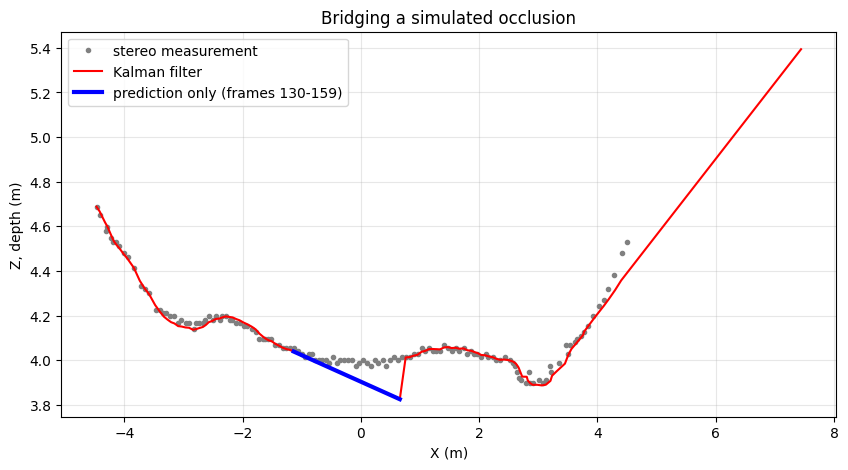

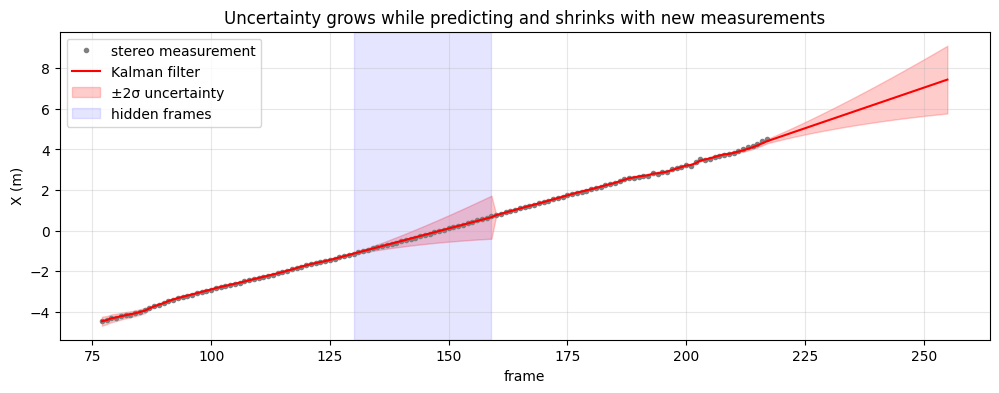

In [8]:
GAP = range(130, 160)          # frames where we pretend the robot is hidden

x = P = None
occ_xyz = np.full((n, 3), np.nan)
occ_std = np.full((n, 3), np.nan)

for k, r in enumerate(results):
    z3 = r["xyz"] if not np.isnan(r["xyz"][0]) else None
    if k in GAP:
        z3 = None                                    # hide the measurement

    if x is None:
        if z3 is not None:
            x, P = start_state(z3, R_3d(z3, r["border"]), vel_var=200**2)
        else:
            continue
    elif z3 is not None:
        x, P = update(x, P, z3.reshape(-1, 1), H3, R_3d(z3, r["border"]))

    occ_xyz[k] = x[0::2, 0] / 1000                   # estimate at this frame (m)
    occ_std[k] = np.sqrt(np.diag(P)[0::2]) / 1000    # its standard deviation (m)
    x, P = predict(x, P, F3, np.zeros_like(x), Q3)

# Error during the gap: predicted position vs the hidden stereo measurement
gap = np.array(list(GAP))
err = np.linalg.norm(occ_xyz[gap] - xyz[gap], axis=1) * 1000
print(f"error during the {len(gap)}-frame gap: mean {np.nanmean(err):.0f} mm, at the end {err[-1]:.0f} mm")
print(f"uncertainty in X: {occ_std[gap[0]-1, 0]*1000:.0f} mm before the gap -> {occ_std[gap[-1], 0]*1000:.0f} mm at its end")

# Plot 1: top-down view with the gap highlighted
plt.figure(figsize=(10, 5))
plt.plot(xyz[:, 0], xyz[:, 2], ".", color="grey", label="stereo measurement")
plt.plot(occ_xyz[:, 0], occ_xyz[:, 2], "r-", label="Kalman filter")
plt.plot(occ_xyz[gap, 0], occ_xyz[gap, 2], "b-", lw=3, label=f"prediction only (frames {gap[0]}-{gap[-1]})")
plt.xlabel("X (m)"); plt.ylabel("Z, depth (m)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Bridging a simulated occlusion")
plt.show()

# Plot 2: X over time with the uncertainty band
plt.figure(figsize=(12, 4))
plt.plot(frames, xyz[:, 0], ".", color="grey", label="stereo measurement")
plt.plot(frames, occ_xyz[:, 0], "r-", label="Kalman filter")
plt.fill_between(frames, occ_xyz[:, 0] - 2 * occ_std[:, 0], occ_xyz[:, 0] + 2 * occ_std[:, 0],
                 color="red", alpha=0.2, label="±2σ uncertainty")
plt.axvspan(gap[0], gap[-1], color="blue", alpha=0.1, label="hidden frames")
plt.xlabel("frame"); plt.ylabel("X (m)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Uncertainty grows while predicting and shrinks with new measurements")
plt.show()

In [9]:
FPS = 15
SCALE = 0.5     # half resolution keeps the file small
H_img, W_img = rectL.shape[:2]
w_s, h_s = int(W_img * SCALE), int(H_img * SCALE)
writer = cv2.VideoWriter("seq1_tracking.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, (2 * w_s, h_s))

trail = []
for k, r in enumerate(results):
    rL, rR = load_pair(k)
    disp_k = stereo.compute(cv2.cvtColor(rL, cv2.COLOR_BGR2GRAY),
                            cv2.cvtColor(rR, cv2.COLOR_BGR2GRAY)).astype(np.float32) / 16.0

    vis = cv2.resize(rL, (w_s, h_s))
    if r["bbox"] is not None:
        x, y, w, h = (int(v * SCALE) for v in r["bbox"])
        col = (0, 165, 255) if r["border"] else (0, 255, 0)      # orange if cut by the border
        cv2.rectangle(vis, (x, y), (x + w, y + h), col, 2)
    if not np.isnan(kf_uv[k, 0]):
        p = (int(kf_uv[k, 0] * SCALE), int(kf_uv[k, 1] * SCALE))
        trail.append(p)
        cv2.circle(vis, p, 5, (0, 0, 255), -1)
    for a, b in zip(trail[:-1], trail[1:]):
        cv2.line(vis, a, b, (0, 0, 255), 2)

    txt = f"frame {k}"
    if not np.isnan(kf_xyz[k, 0]):
        txt += f"   X = {kf_xyz[k, 0]:+.2f} m   Z = {kf_xyz[k, 2]:.2f} m"
    elif r["detected"]:
        txt += "   (no disparity at the left border)"
    (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
    cv2.rectangle(vis, (5, 5), (15 + tw, 15 + th), (0, 0, 0), -1)          # dark box behind the text
    cv2.putText(vis, txt, (10, 10 + th), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)

    d8 = np.clip(disp_k * 255 / 60, 0, 255).astype(np.uint8)
    dcol = cv2.applyColorMap(cv2.resize(d8, (w_s, h_s), interpolation=cv2.INTER_NEAREST), cv2.COLORMAP_JET)
    dcol[cv2.resize(d8, (w_s, h_s), interpolation=cv2.INTER_NEAREST) == 0] = 0    # invalid = black
    cv2.putText(dcol, "StereoBM disparity", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)

    writer.write(np.hstack([vis, dcol]))

writer.release()
print("saved seq1_tracking.mp4")

saved seq1_tracking.mp4


In [10]:
%matplotlib qt
# ↑ opens the plot in its own window so you can rotate it with the mouse.
#   If you get an error about Qt, run  pip install pyqt5  and restart the kernel.
#   Put  %matplotlib inline  in a later cell to go back to plots inside the notebook.

from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import MultipleLocator

# --- Scene point cloud from an empty frame (frame 0), same StereoBM as Step 2 ---
rL0, rR0 = load_pair(0)
disp0 = stereo.compute(cv2.cvtColor(rL0, cv2.COLOR_BGR2GRAY),
                       cv2.cvtColor(rR0, cv2.COLOR_BGR2GRAY)).astype(np.float32) / 16.0
pts0 = cv2.reprojectImageTo3D(disp0, Q) / 1000                       # metres
m0 = (disp0 > 0) & (pts0[..., 2] > 0.5) & (pts0[..., 2] < 12)        # valid, closer than 12 m
cloud = pts0[m0]
rgb = cv2.cvtColor(rL0, cv2.COLOR_BGR2RGB)[m0] / 255
sel = np.random.default_rng(0).choice(len(cloud), min(20000, len(cloud)), replace=False)

# --- 3D map: X (right), Z (depth), height = -Y (up) ---
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(cloud[sel, 0], cloud[sel, 2], -cloud[sel, 1], c=rgb[sel], s=1, alpha=0.5, label="scene point cloud")
ax.scatter(xyz[:, 0], xyz[:, 2], -xyz[:, 1], c="grey", s=6, label="stereo measurement")
ax.plot(kf_xyz[:, 0], kf_xyz[:, 2], -kf_xyz[:, 1], "k-", lw=3, label="trajectory (Kalman filter)")

valid = np.where(~np.isnan(kf_xyz[:, 0]))[0]
i0, i1 = valid[0], valid[-1]
ax.scatter(*kf_xyz[i0, [0, 2]], -kf_xyz[i0, 1], marker="s", s=120, facecolors="none", edgecolors="tab:blue", linewidths=2, label="start")
ax.scatter(*kf_xyz[i1, [0, 2]], -kf_xyz[i1, 1], marker="v", s=120, facecolors="none", edgecolors="m", linewidths=2, label="end")
ax.scatter(0, 0, 0, marker="^", s=150, c="black", label="left camera")

# 1 m x 1 m grid
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_major_locator(MultipleLocator(1.0))
ax.set_xlim(-6, 6); ax.set_ylim(0, 12); ax.set_zlim(-1, 3)
ax.set_box_aspect((12, 12, 4))                                       # equal scale on all axes
ax.set_xlabel("X (m)"); ax.set_ylabel("Z, depth (m)"); ax.set_zlabel("height (m)")
ax.set_title("Sequence 1: 3D map (drag to rotate, 1 m grid)")
ax.view_init(elev=25, azim=-60)
ax.legend(loc="upper left", fontsize=8)
plt.show()